# Heijunka (levelled) kit release with workcell setups and SPC

Copy of `phase2_assumptions_simulation.ipynb` that swaps the equal M860 → M970 → M1080 rotation for `release_mode="heijunka"` (README, Experiment 3). Everything else is unchanged: the station-group setup assumptions in [phase2_assumptions.md](phase2_assumptions.md), Year 3 resources, 75% setup reductions at every station (relative to the original project inputs; previously reduced stations are not reduced again), and SPC in both cells.

**Operational interpretation:**
- A workcell set means all parallel machines at one numbered station (for example, all six machines at 5-A), rather than all of Fabrication or Assembly.
- The complete station is set up once for **each product lot**, even when an earlier lot of that model was prepared. Setup happens when its first unit reaches the head of the station queue. Existing station work and maintenance finish first; all station machines are reserved during setup and while waiting for the setup team.
- Setup labor is `machine count × efficiency-adjusted setup time`. Elapsed setup is that labor divided by the assigned setup crew. Crew defaults to the station machine count; `SETUP_CREW` below overrides it. Operators come from the existing shared cell pools and are unavailable elsewhere while setting up. Crews are acquired atomically, in the pool's priority/FIFO order.
- A prepared lot remains ready at that station until it finishes. Its units can share machines with any other prepared product without further per-unit changeover setup. Zero setup inputs stay zero.
- **Arrivals (the change in this notebook):** one kit per recalculated arrival interval, with no station lot gates or WIP cap, in a **deterministic level sequence weighted by each model's planned kit volume**. Before each kit, the model furthest behind its kit share is released, so every model's kits, and its good output, arrive at an even rate matching its own demand. The cyclic rotation instead gives each model one third of the kits. The kit shares are printed below; they shift slightly with SPC because scrap allowances change.
- EOQ group identifiers retain the existing branch quantities, scrap planning, and component matching. They do not impose processing batches: matched assemblies leave immediately when their components are available.

These choices make the prose assumptions concrete. In particular, the station is unavailable during its group setup; prepared products may mix freely afterward. Part flow time starts at the oldest constituent kit's actual arrival; WIP counts component and assembly items.

**SPC in both cells:** Fabrication (1–8) and Assembly (9–12) use `scrap_scale=0.25`, a 75% reduction in every station/model scrap probability. Zero scrap stays zero. Scrap allowances, component requirements, and kit interarrival time are recalculated for the same planned finished output; therefore fewer input kits are required. The input table below reports the actual recalculated arrival interval.

## 1. Scenario inputs and setup crews

Change `YEAR` and `SETUP_CREW` here. This notebook uses the station-group setup policy throughout the detailed run. The tables show resources, product inputs, and elapsed setup times after efficiency and crew adjustment.

In [1]:
import os
import itertools
from dataclasses import replace
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from lcd_sim.params import get_scenario, MODELS, STATIONS, STATION_INFO
from lcd_sim.stats import run, run_replications
from lcd_sim import plots as P

YEAR = 3
N_REPS = 10
N_JOBS = max(1, min(8, (os.cpu_count() or 2) - 1))
SPC_SCRAP_SCALE = 0.25  # SPC in both Fab and Asm: 75% less scrap
SETUP_CREW = {}   # e.g. {"5-A": 3}; default is one operator per machine at each station
sc = get_scenario(YEAR, release_mode="heijunka", setup_scope="workcell", setup_crew=SETUP_CREW, scrap_scale=SPC_SCRAP_SCALE)
print(f"Year {YEAR}; {sc.warmup_weeks}-week warm-up; {sc.run_weeks}-week measurement")
kits = sc.annual_kits()
print(f"Arrivals: heijunka level sequence; {sc.kit_interarrival_min:.4f} productive min/kit")
print("Kit shares: " + ", ".join(f"{m} {kits[m] / sum(kits.values()):.1%}" for m in MODELS))
print("First 30 kits:", " ".join(m[1:] for m in itertools.islice(sc.heijunka_sequence(), 30)))
print(f"Operators per shift: {sc.operators}")
station_inputs, product_inputs = sc.describe()
display(product_inputs)
display(station_inputs)
setup_inputs = pd.DataFrame([
    {"Station": ws, "Machines": sc.machines[ws],
     "Setup crew": sc.setup_crew.get(ws, sc.machines[ws]),
     **{f"{model} elapsed setup (min)": sc.machines[ws] * sc.op_times(model, ws)["setup"] / sc.setup_crew.get(ws, sc.machines[ws])
        if station_inputs.loc[ws, f"Time/part {model}"] > 0 else None for model in MODELS}}
    for ws in STATIONS
]).set_index("Station")
display(setup_inputs)

pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:,.3f}".format)
print(f"SPC: Fab and Asm scrap probabilities multiplied by {sc.scrap_scale:.2f}")
scrap_inputs = pd.DataFrame({model: {ws: sc.scrap_rate(model, ws) for ws in STATIONS} for model in MODELS})
scrap_inputs.index.name = "Station"
display(scrap_inputs.rename(columns=lambda model: f"{model} scrap probability"))

C:\Users\djhic\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Year 3; 2-week warm-up; 8-week measurement
Arrivals: heijunka level sequence; 1.1834 productive min/kit
Kit shares: M860 35.8%, M970 30.3%, M1080 33.9%
First 30 kits: 860 1080 970 860 1080 970 860 1080 970 860 1080 970 860 1080 970 860 1080 970 860 1080 860 970 1080 860 970 1080 860 970 1080 860
Operators per shift: {'Fab': 7, 'Asm': 13}


,Demand,EOQ,Lots_per_year,Planned_yield,Sent to KIT (1-M),Sent to KB (4-A),Sent to DISP (2-M),Sent to PWR (3-A/5-A),Sent to BL (6-A),Sent to ASM (7-M/8-A/9-M/10-M/11-A/12-M),Kits_per_year,Sent to ASM (8-A/9-M/10-M/11-A/12-M)
Model,,,,,,,,,,,,
M860,63877,754,85,0.9415,801,791,801,799,787,785.0,68085,NaN
M970,55296,596,93,0.9614,620,614,620,620,613,NaN,57660,611.0
M1080,61516,655,94,0.9565,685,676,685,684,674,NaN,64390,672.0


,Description,Type,Cell,Machines,Efficiency,Time/part M860,Time/part M970,Time/part M1080,Setup M860,Setup M970,...,Qty/lot M970,Qty/lot M1080,Scrap factor M860,Scrap factor M970,Scrap factor M1080,PM_every_units,PM_min,MTBF_hr,Repair_min,Units_between_failures
Station,,,,,,,,,,,,,,,,,,,,,
1-M,Unpack and label components,M,Fab,2,0.90,1.742,1.851,2.287,4.17,0.00,...,620.0,685.0,1.0621,1.0402,1.0455,NaN,NaN,NaN,NaN,NaN
2-M,Sanitize LC displays and PCBs,M,Fab,2,0.95,1.135,1.548,1.651,5.26,0.00,...,620.0,685.0,1.0621,1.0402,1.0455,NaN,NaN,100.0,10.0,4182.0
3-A,Connect display to power strip,A,Fab,2,1.05,0.564,1.404,1.686,1.19,2.38,...,620.0,684.0,1.0595,1.0389,1.0441,12000.0,10.0,50.0,30.0,2502.0
4-A,Tack keyboard inputs to display,A,Fab,1,1.02,0.969,0.484,0.678,1.96,2.45,...,614.0,676.0,1.0489,1.0298,1.0308,12000.0,20.0,75.0,60.0,6221.0
5-A,Bond power strip to PCB and LCD,A,Fab,6,0.99,2.697,6.459,7.251,3.79,15.15,...,620.0,684.0,1.0542,1.0350,1.0408,12000.0,20.0,250.0,120.0,2787.0
6-A,Insert backlights and sensors,A,Fab,3,0.95,1.242,1.964,3.308,2.63,0.00,...,613.0,674.0,1.0436,1.0272,1.0277,6000.0,10.0,60.0,60.0,1666.0
7-M,Verify alignment and bonds,M,Fab,1,0.90,1.316,NaN,NaN,3.33,NaN,...,NaN,NaN,1.0410,NaN,NaN,NaN,NaN,100.0,15.0,4561.0
8-A,Power up test on components,A,Fab,2,0.95,1.350,1.556,2.074,2.63,2.63,...,611.0,672.0,1.0332,1.0246,1.0251,6000.0,10.0,250.0,90.0,9050.0
9-M,Solder subassemblies and connectors,M,Asm,6,0.93,3.372,7.272,8.642,1.34,0.00,...,611.0,672.0,1.0228,1.0169,1.0175,NaN,NaN,NaN,NaN,NaN


,Machines,Setup crew,M860 elapsed setup (min),M970 elapsed setup (min),M1080 elapsed setup (min)
Station,,,,,
1-M,2,2,4.166667,0.000000,0.000000
2-M,2,2,5.263158,0.000000,0.000000
3-A,2,2,1.190476,2.380952,2.857143
4-A,1,1,1.960784,2.450980,3.431373
5-A,6,6,3.787879,15.151515,16.414141
6-A,3,3,2.631579,0.000000,0.000000
7-M,1,1,3.333333,NaN,NaN
8-A,2,2,2.631579,2.631579,3.947368
9-M,6,6,1.344086,0.000000,0.000000


SPC: Fab and Asm scrap probabilities multiplied by 0.25


,M860 scrap probability,M970 scrap probability,M1080 scrap probability
Station,,,
1-M,0.000,0.000,0.000
2-M,0.003,0.001,0.001
3-A,0.005,0.004,0.003
4-A,0.007,0.005,0.005
5-A,0.013,0.010,0.015
6-A,0.003,0.003,0.003
7-M,0.007,0.000,0.000
8-A,0.010,0.007,0.007
9-M,0.010,0.007,0.007


## 2. Plant flow and model checks

One replication illustrates the assumptions. Charts with a grey warm-up band include the initial two weeks; summary statistics use the following eight weeks. A station-group setup reserves every machine at that station. Prepared product lots can then share the station without per-unit changeover setup.

Accounting and operator checks: {'lot violations (must be 0)': 0, 'closed lots with items still owed (must be 0)': 0, 'negative owed counts (must be 0)': 0, 'finished > EOQ x plan (must be 0)': 0, 'max operator utilization (<= 1)': 0.8451539639133004}


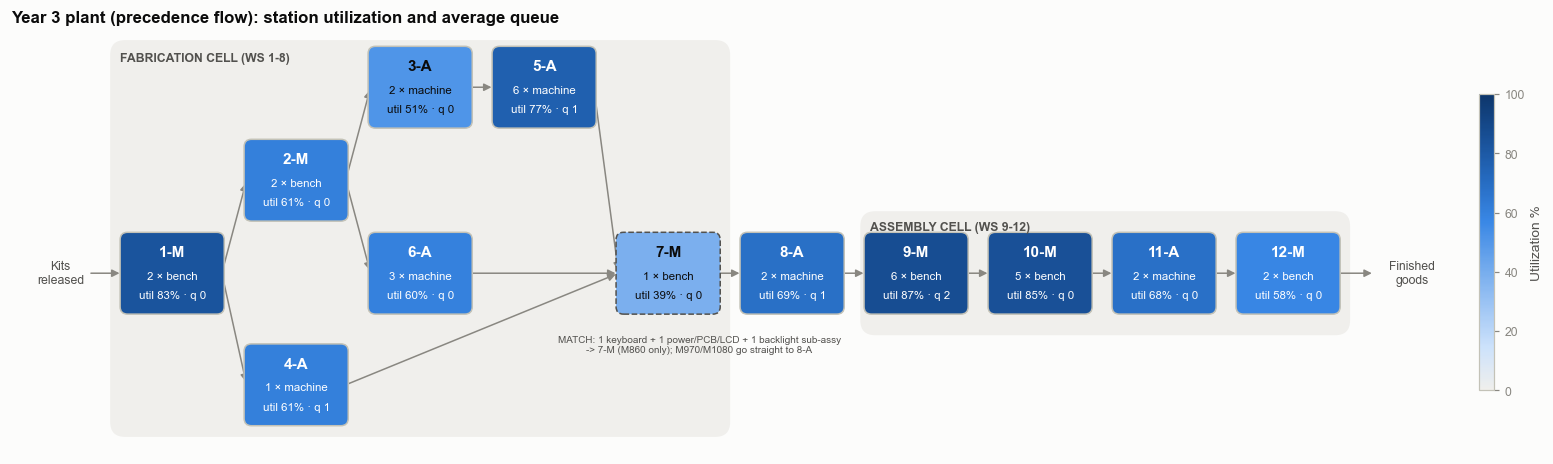

In [2]:
res = run(sc)
assert all(value == 0 for key, value in res.checks.items() if "must be 0" in key), res.checks
assert res.checks["max operator utilization (<= 1)"] <= 1 + 1e-9
assert (res.stations["Gate-blocked %"] == 0).all()
print("Accounting and operator checks:", res.checks)
P.plot_block_diagram(res); plt.show()


## 3. Throughput by product versus demand

Read each product separately. With the heijunka sequence, each model's kits arrive in proportion to its own kit volume, so each model's weekly output should sit close to its own dashed demand line. The remaining week-to-week variation comes from scrap, breakdowns, and maintenance, not from the release.

,Finished,Per week,Demand per week,% of demand,Avg flow time (hr),P90 flow time (hr)
Model,,,,,,
M860,"10,224.000","1,278.000","1,277.540",1.000,0.790,0.858
M970,"8,841.000","1,105.125","1,105.920",0.999,0.926,1.331
M1080,"9,846.000","1,230.750","1,230.320",1.000,1.032,1.056
Total,"28,911.000","3,613.875","3,613.780",1.000,0.914,1.077


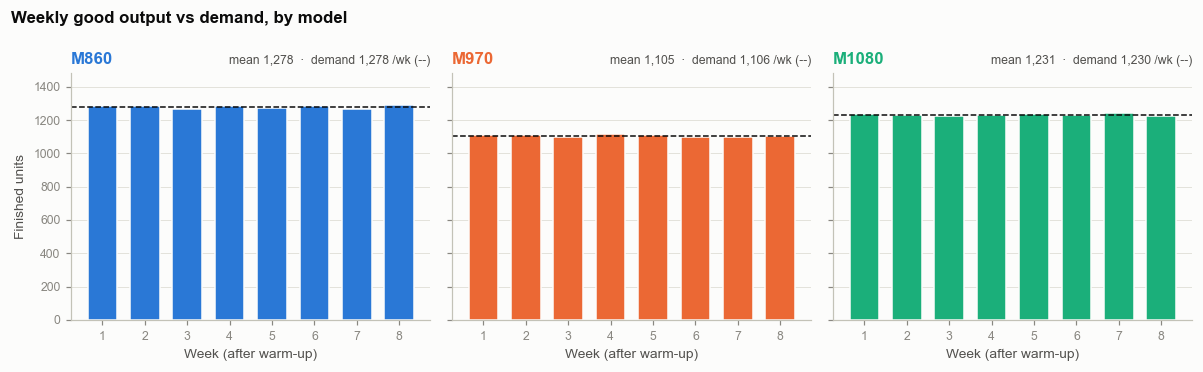

In [3]:
display(res.throughput)
P.plot_throughput(res); plt.show()


## 4. Queues, WIP, and matching

Daily station bars show waiting units by product; the detailed lines show the time pattern. No lot gates are used in this policy.

**Waiting at the match** is the component buffer after fabrication branches 4-A, 5-A, and 6-A. It is separate from station 7. One keyboard, one power/PCB/LCD, and one backlight subassembly from the same product lot must be available before an assembly moves to 7-M (M860) or directly to 8-A (M970/M1080). Waiting components count as WIP and occupy no operators or machines.

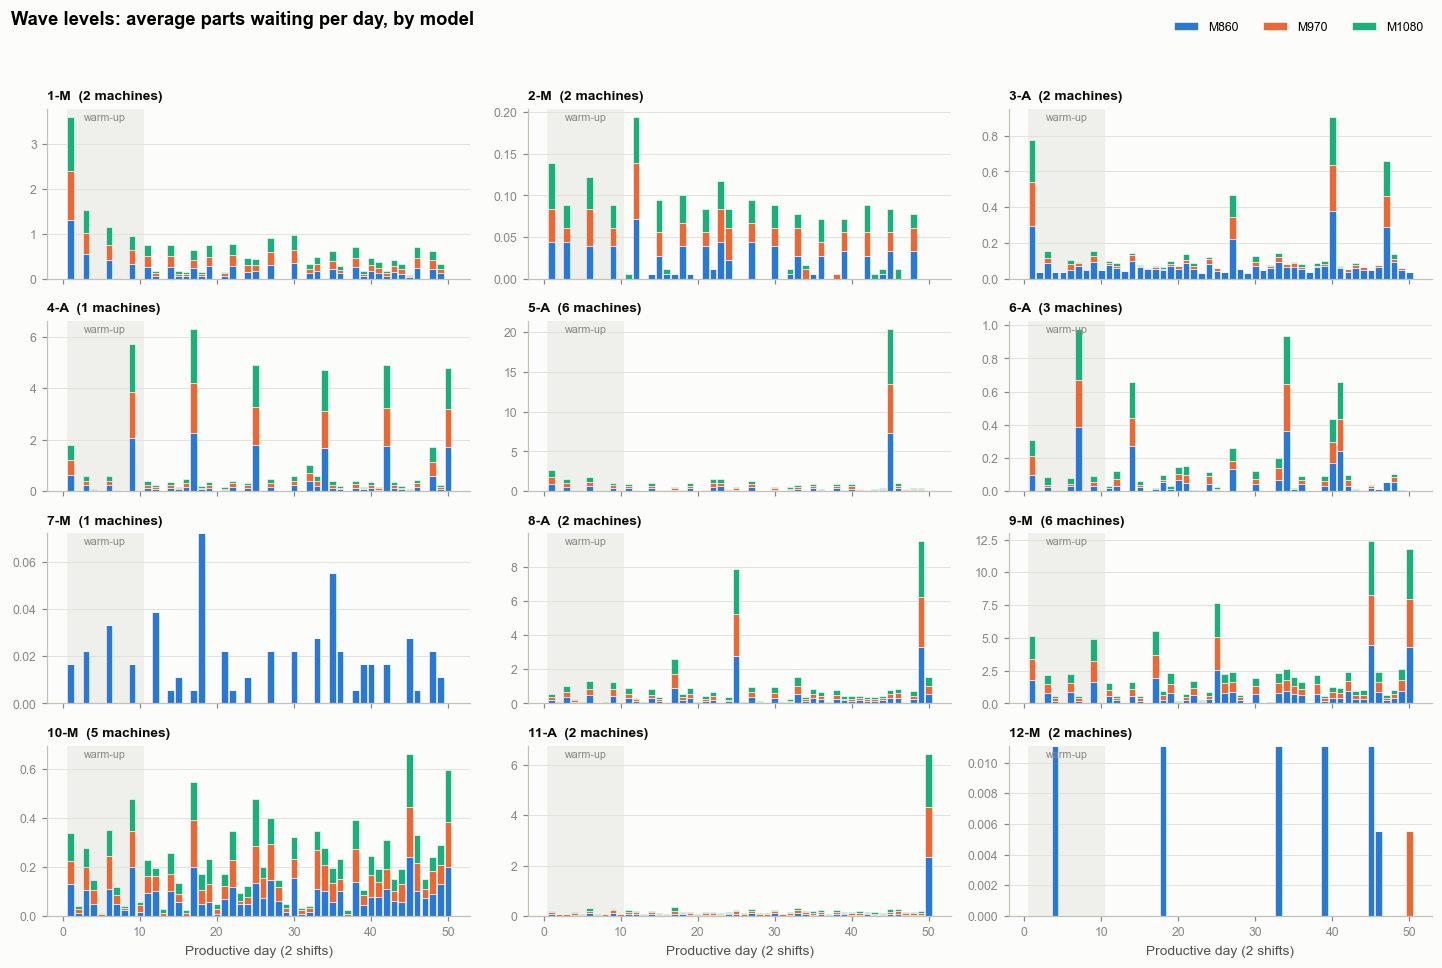

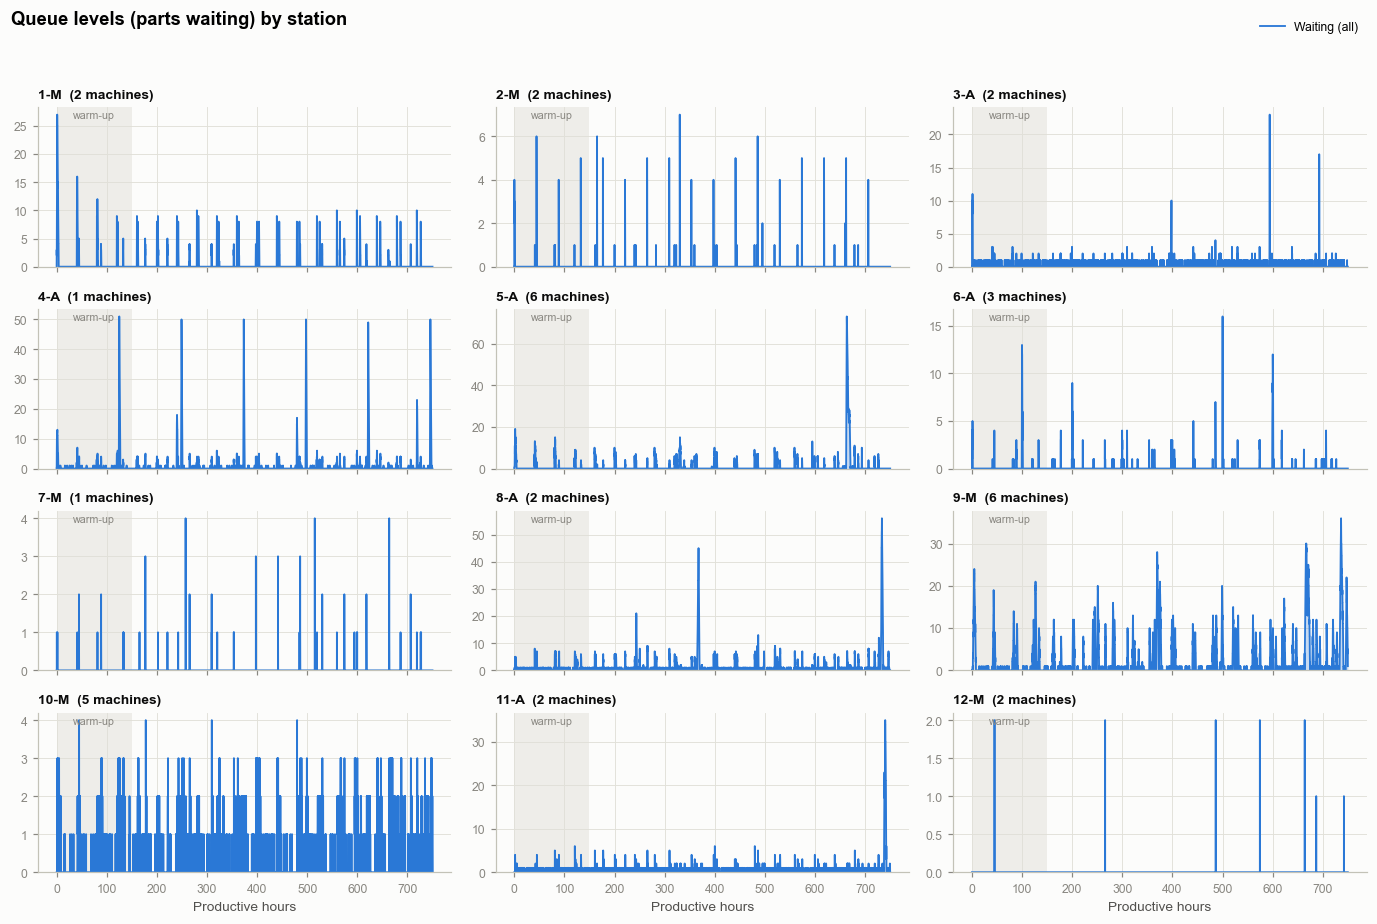

In [4]:
P.plot_wave_levels(res); plt.show()
P.plot_queue_lines(res, gated=False); plt.show()


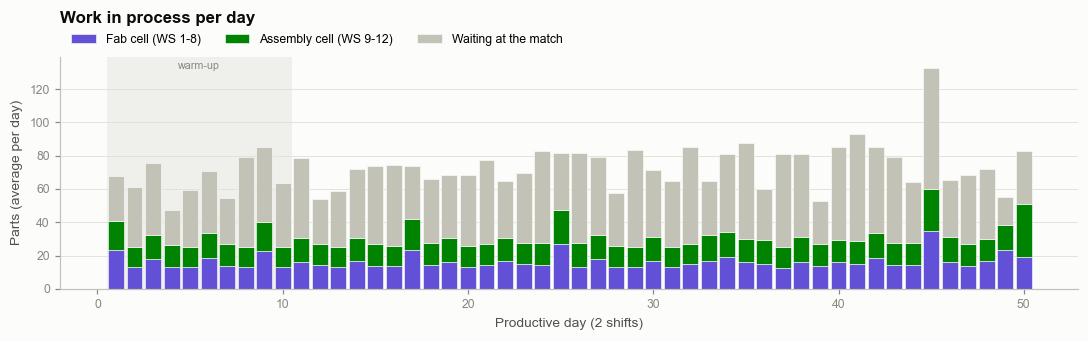

WIP near measurement start/end: 72 / 64 items
Net change: -8 items
Time-average WIP: 74.4 component/assembly items


In [5]:
P.plot_wip(res); plt.show()
window = res.trace[res.trace.t >= sc.warmup_min]
print(f"WIP near measurement start/end: {window.iloc[0]['WIP']:,.0f} / {window.iloc[-1]['WIP']:,.0f} items")
print(f"Net change: {window.iloc[-1]['WIP'] - window.iloc[0]['WIP']:,.0f} items")
print(f"Time-average WIP: {res.kpis['WIP|Average WIP (parts)']:,.1f} component/assembly items")


## 5. Station utilization and capacity

Utilization includes processing plus setup. The historical Phase 1 comparison and processing-only capacity estimates are reference values based on the original planned mix; the heijunka sequence uses that same planned kit mix. Capacity bars exclude setup, operator waiting, and downtime.

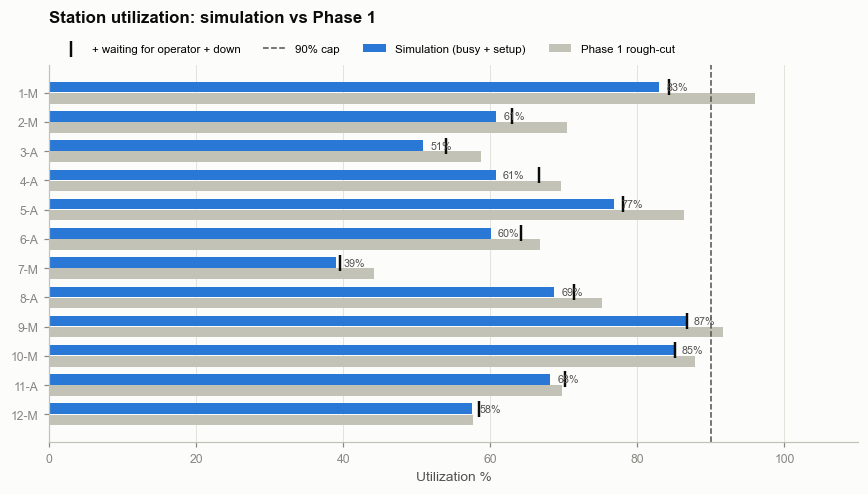

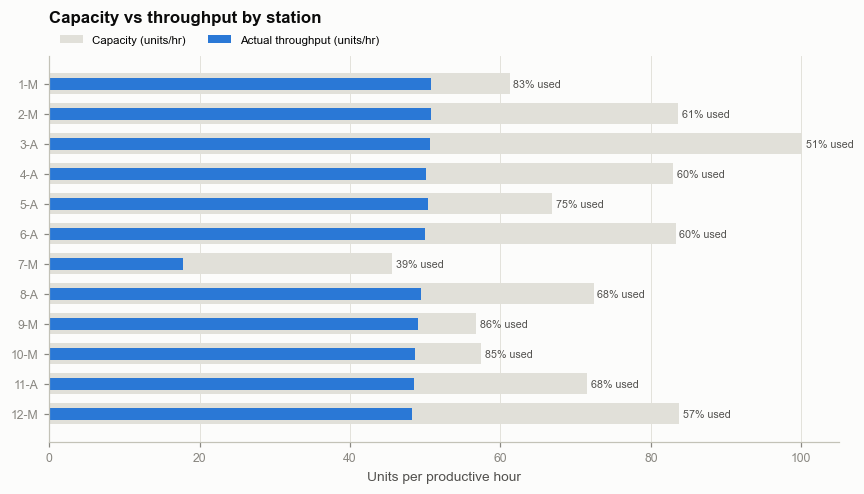

,Cell,Machines,Utilization,Busy %,Setup %,WaitOp %,Down %,Idle %,Capacity (units/hr),Throughput (units/hr),Avg queue,Max queue,Avg wait (min),Wait for operator (min/part),Group setups
Station,,,,,,,,,,,,,,,
1-M,Fab,2,0.830,0.828,0.002,0.014,0.000,0.157,61.230,50.703,0.334,10.000,0.395,0.033,13
2-M,Fab,2,0.608,0.606,0.002,0.020,0.001,0.371,83.642,50.703,0.037,9.000,0.044,0.048,13
3-A,Fab,2,0.508,0.506,0.003,0.027,0.005,0.460,100.091,50.602,0.121,23.000,0.144,0.063,43
4-A,Fab,1,0.607,0.604,0.003,0.049,0.010,0.334,82.950,50.095,0.904,51.000,1.083,0.059,43
5-A,Fab,6,0.768,0.753,0.015,0.005,0.007,0.220,66.894,50.372,0.946,75.000,1.127,0.032,43
6-A,Fab,3,0.600,0.599,0.001,0.031,0.011,0.358,83.299,49.932,0.113,17.000,0.136,0.110,13
7-M,Fab,1,0.390,0.389,0.001,0.004,0.001,0.605,45.605,17.730,0.011,5.000,0.038,0.014,13
8-A,Fab,2,0.687,0.683,0.004,0.020,0.006,0.287,72.403,49.457,0.971,57.000,1.177,0.049,43
9-M,Asm,6,0.866,0.866,0.000,0.001,0.000,0.133,56.767,49.067,2.016,38.000,2.466,0.006,13


In [6]:
P.plot_utilization(res); plt.show()
P.plot_capacity(res); plt.show()
display(res.stations[["Cell", "Machines", "Utilization", "Busy %", "Setup %", "WaitOp %", "Down %", "Idle %",
                      "Capacity (units/hr)", "Throughput (units/hr)", "Avg queue", "Max queue", "Avg wait (min)",
                      "Wait for operator (min/part)", "Group setups"]])


## 6. Machine states and individual machines

The station chart aggregates parallel machines. The heatmap and machine chart expose uneven loading. During a group setup, all participating machines are in Setup; while the setup team is being acquired, they are in Waiting for operator.

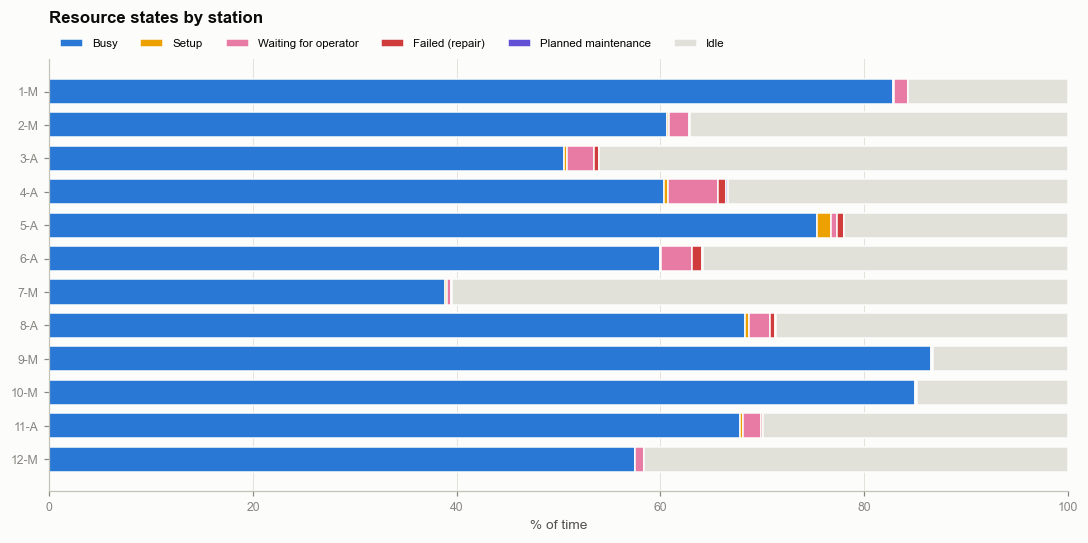

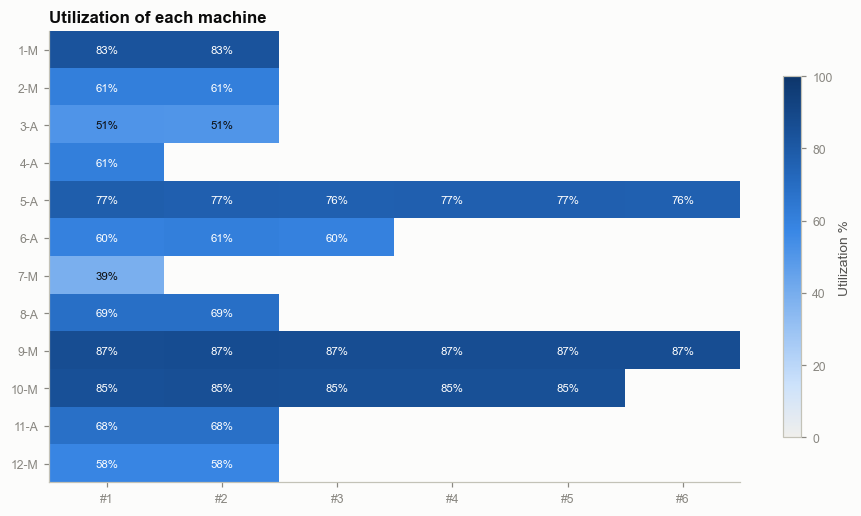

In [7]:
P.plot_machine_states(res, by="station"); plt.show()
P.plot_machine_heatmap(res); plt.show()


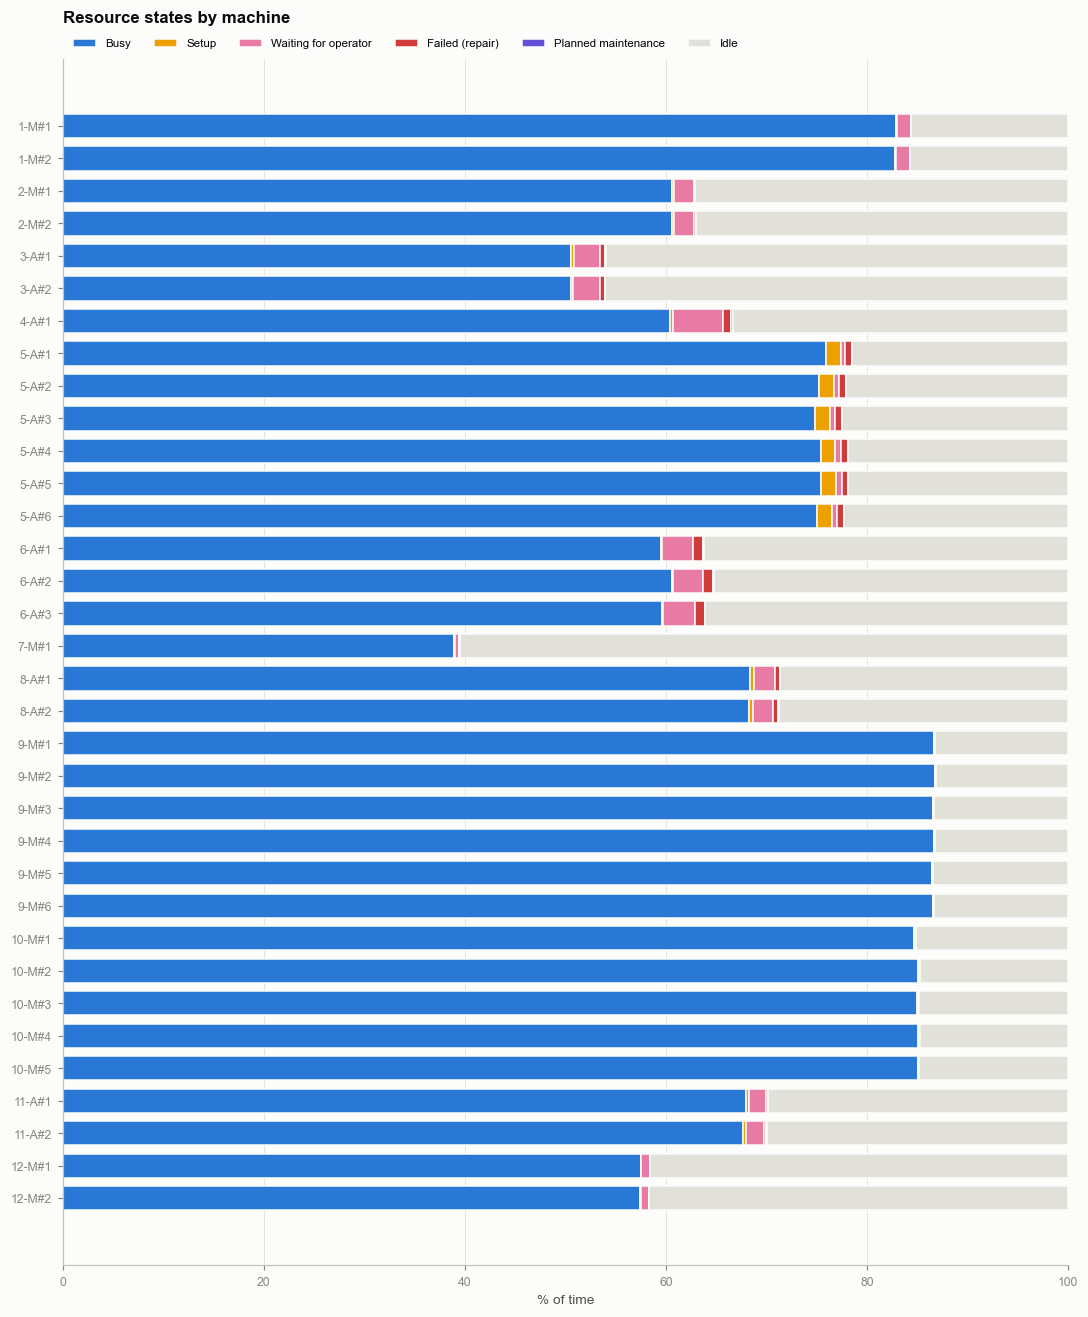

In [8]:
P.plot_machine_states(res, by="machine"); plt.show()
# display(res.machines)


## 7. Operator workload and activity

Setup crews draw from the same cell operator pools used for normal processing. Daily busy-operator plots show demand against staffing. Gantt charts show the first four logged hours after warm-up, with colors indicating station assignment; simultaneous team assignments appear on multiple operator rows.

,Crew per shift,Scheduled labor-hr,Busy labor-hr,Idle labor-hr,Avg busy,Peak busy,Utilization,Avg WIP in cell,Avg wait for operator (min/part),Avg wait for machine (min/part)
Cell,,,,,,,,,,
Fab,7,"4,200.000","3,244.660",955.340,5.408,7.000,0.773,16.327,0.054,0.558
Asm,13,"7,800.000","6,576.039","1,223.961",10.960,13.000,0.843,14.577,0.019,0.791


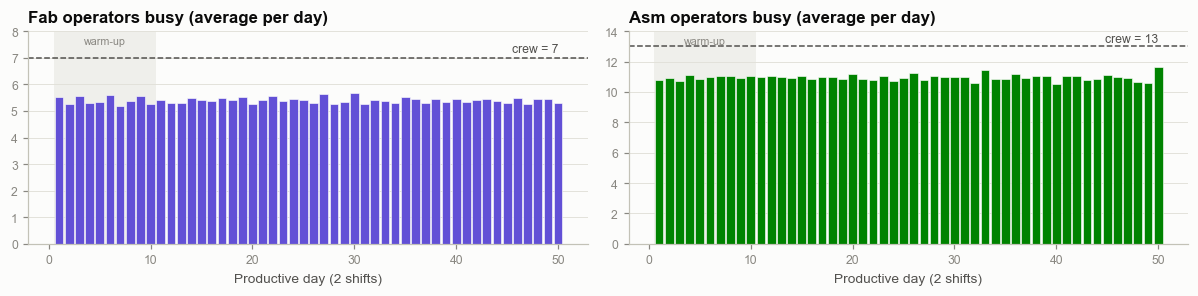

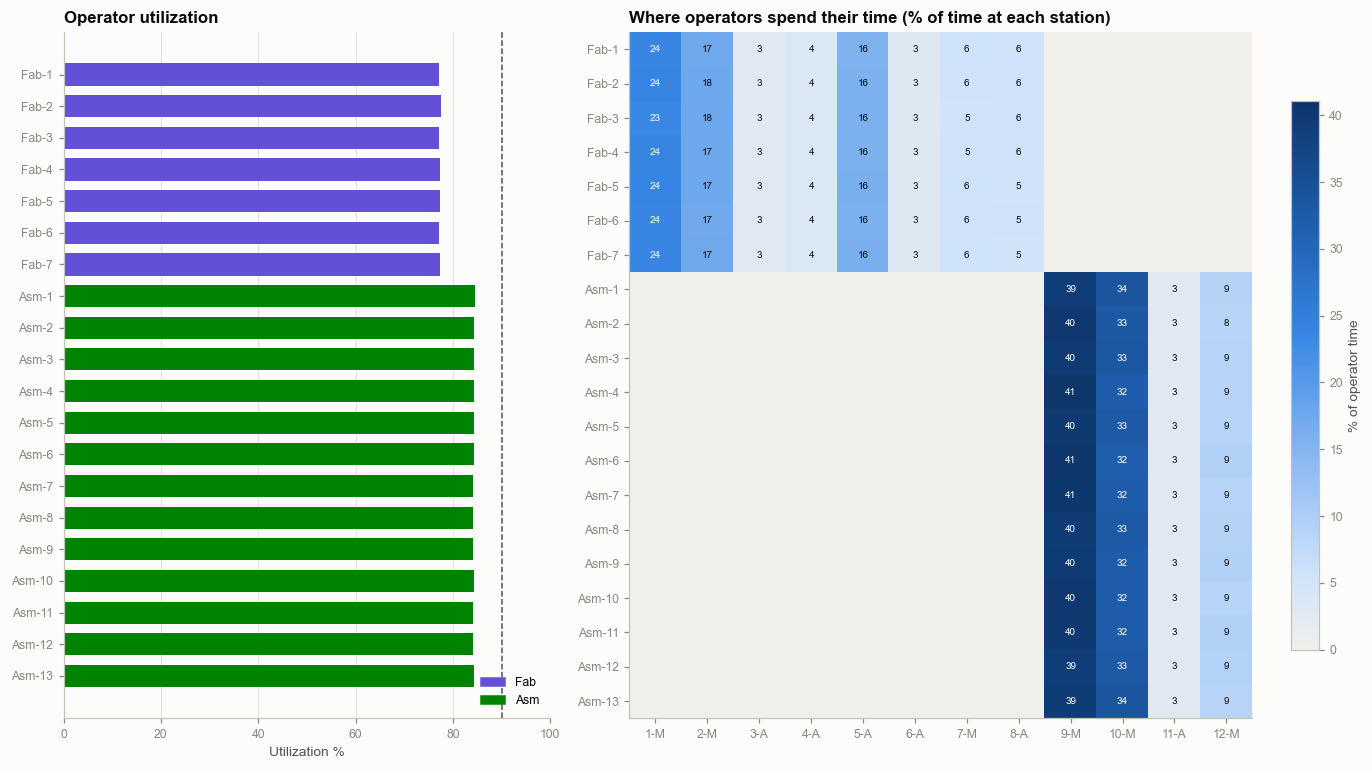

,Cell,Busy (hr),Utilization,Main station,1-M hr,2-M hr,3-A hr,4-A hr,5-A hr,6-A hr,7-M hr,8-A hr,9-M hr,10-M hr,11-A hr,12-M hr
Fab-1,Fab,462.570,0.771,1-M,142.000,103.100,16.900,21.800,93.300,17.900,33.900,33.500,0.000,0.000,0.000,0.000
Fab-2,Fab,464.827,0.775,1-M,142.900,105.400,16.300,21.500,94.400,17.800,33.400,33.100,0.000,0.000,0.000,0.000
Fab-3,Fab,463.087,0.772,1-M,140.200,105.600,16.900,22.000,94.900,17.900,32.200,33.400,0.000,0.000,0.000,0.000
Fab-4,Fab,464.014,0.773,1-M,143.500,104.600,16.300,21.700,94.000,17.900,32.800,33.200,0.000,0.000,0.000,0.000
Fab-5,Fab,463.972,0.773,1-M,142.800,104.100,16.100,21.400,95.800,17.800,33.900,32.100,0.000,0.000,0.000,0.000
Fab-6,Fab,462.377,0.771,1-M,141.700,102.800,17.000,21.600,95.000,17.800,33.500,32.900,0.000,0.000,0.000,0.000
Fab-7,Fab,463.783,0.773,1-M,142.400,104.000,16.300,21.700,95.400,17.600,34.400,32.100,0.000,0.000,0.000,0.000
Asm-1,Asm,507.092,0.845,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,235.400,202.300,16.000,53.300
Asm-2,Asm,506.322,0.844,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,241.700,198.600,16.000,50.100
Asm-3,Asm,506.300,0.844,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,238.300,199.900,16.700,51.400


In [9]:
display(res.cells)
P.plot_operators_busy(res); plt.show()
P.plot_operators(res); plt.show()
display(res.operators.join((res.op_station / 60).round(1).add_suffix(" hr")))


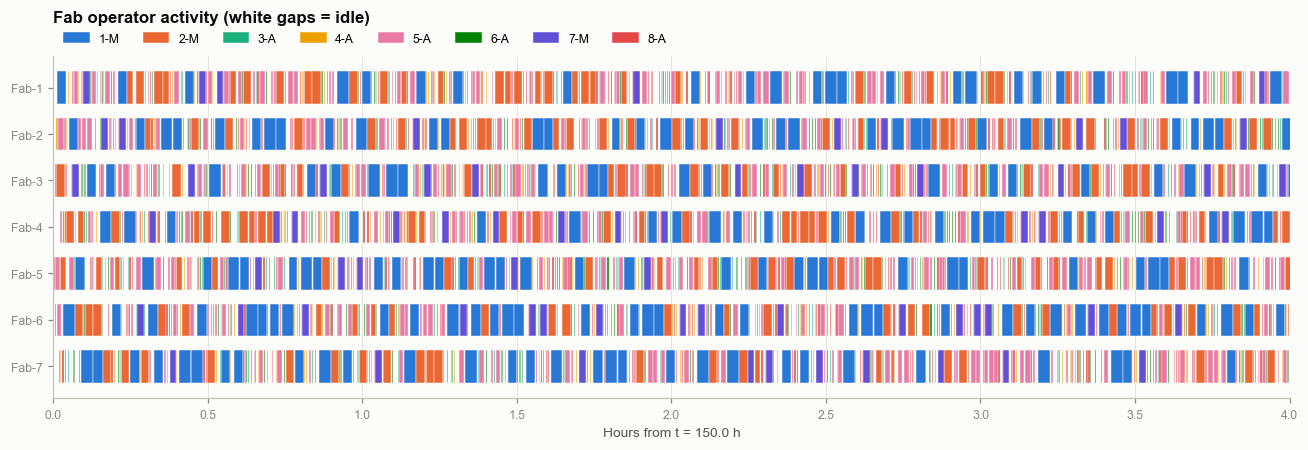

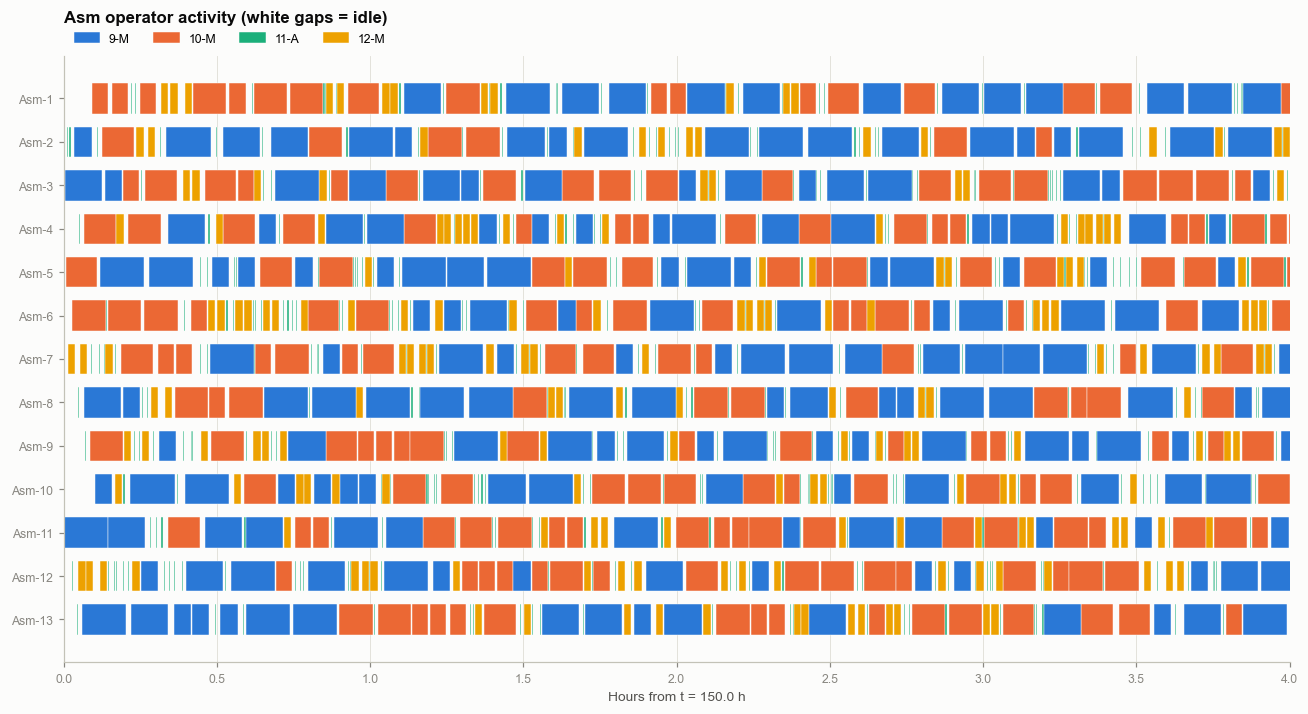

In [10]:
P.plot_operator_gantt(res, cell="Fab", hours=4); plt.show()
P.plot_operator_gantt(res, cell="Asm", hours=4); plt.show()


## 8. Station-group setups and team labor

Group setups count whole-station events during the measurement window. Machine setups count each participating machine: one event at 5-A contributes six machine setups. The event table and crew chart use the first logged week after warm-up; the event-count chart uses the complete eight-week measurement period.

,Station,Lot,Model,Start,End,Crew,Elapsed min,Operator min
0,1-M,15,M860,"10,591.079","10,595.246",2,4.167,8.333
1,1-M,18,M860,"13,237.094","13,241.260",2,4.167,8.333
2,10-M,15,M860,"10,633.243","10,634.631",5,1.389,6.944
3,10-M,18,M860,"13,278.532","13,279.921",5,1.389,6.944
4,11-A,13,M1080,"9,638.689","9,642.439",2,3.750,7.500
5,11-A,14,M970,"9,730.342","9,732.842",2,2.500,5.000
6,11-A,15,M860,"10,637.790","10,640.290",2,2.500,5.000
7,11-A,16,M1080,"12,030.565","12,034.315",2,3.750,7.500
8,11-A,17,M970,"12,149.385","12,151.885",2,2.500,5.000
9,11-A,18,M860,"13,283.079","13,285.579",2,2.500,5.000


,Machines,Group setups,Setups,Setup %,WaitOp %
Station,,,,,
1-M,2,13,26,0.002,0.014
2-M,2,13,26,0.002,0.020
3-A,2,43,86,0.003,0.027
4-A,1,43,43,0.003,0.049
5-A,6,43,258,0.015,0.005
6-A,3,13,39,0.001,0.031
7-M,1,13,13,0.001,0.004
8-A,2,43,86,0.004,0.020
9-M,6,13,78,0.000,0.001


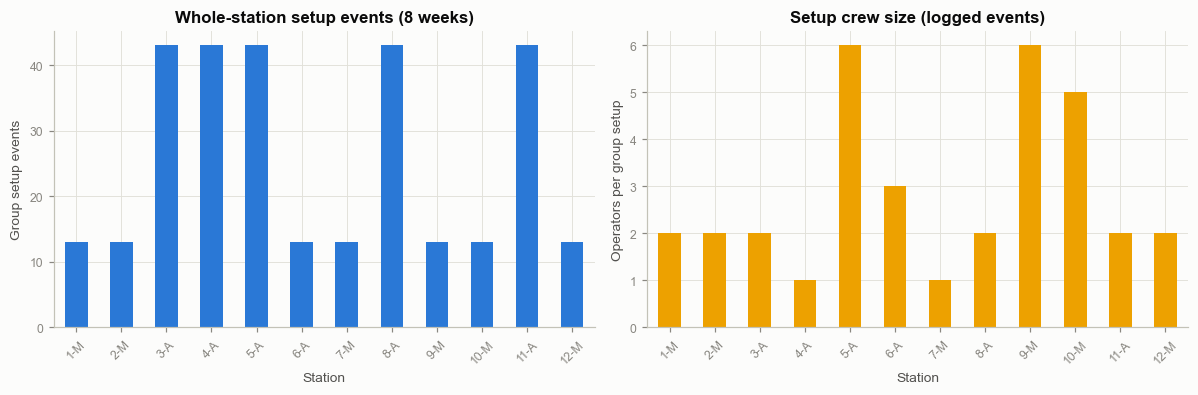

In [11]:
setup_tasks = res.op_log[res.op_log.Task == "setup"].copy()
events = pd.DataFrame()
if not setup_tasks.empty:
    events = setup_tasks.groupby(["Station", "Lot", "Model", "Start", "End"]).agg(Crew=("Operator", "nunique")).reset_index()
    events["Elapsed min"] = events.End - events.Start
    events["Operator min"] = events["Elapsed min"] * events.Crew
    display(events.head(25))
display(res.stations[["Machines", "Group setups", "Setups", "Setup %", "WaitOp %"]])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
res.stations["Group setups"].reindex(STATIONS).plot.bar(ax=axes[0], color="#2a78d6", rot=45)
axes[0].set_title("Whole-station setup events (8 weeks)")
axes[0].set_ylabel("Group setup events")
if not events.empty:
    observed = events.groupby("Station").Crew.mean().reindex(STATIONS)
    observed.plot.bar(ax=axes[1], color="#eda100", rot=45)
axes[1].set_title("Setup crew size (logged events)")
axes[1].set_ylabel("Operators per group setup")
fig.tight_layout(); plt.show()


## 9. Scrap, spare components, and lot completion

Scrap is measured per entity: a kit, component, or assembled display. Unneeded branch outputs are counted as spare; unmatched components left when their accounting group closes are counted separately. EOQ identifiers are accounting and matching groups, not station processing restrictions.

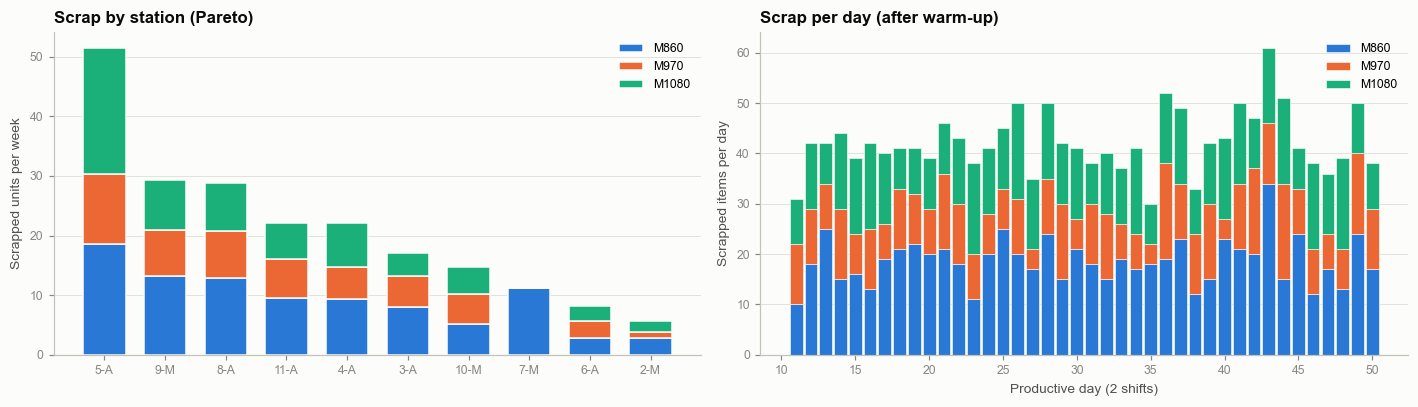

Units per week  Invested_min per week  Labor_dollars per week
Station Item                         Model                                                               
10-M    Display assembly             M1080           4.500                181.500                  35.700
                                     M860            5.100                113.600                  25.300
                                     M970            5.100                174.200                  35.500
11-A    Display assembly             M1080           6.100                257.900                  49.700
                                     M860            9.500                226.500                  49.200
                                     M970            6.500                231.200                  45.900
2-M     LCD/PCB set                  M1080           1.900                  7.400                   1.900
                                     M860            2.800                  7.900                   2.600
                                     M970            1.000                  3.400                   0.900
3-A     Power strip/PCB/LCD sub-assy M1080           3.900                 21.800                   4.300
                                     M860            8.000                 27.500                   6.400
                                     M970            5.200                 25.200                   4.900
4-A     Keyboard sub-assy            M1080           7.400                 21.900                   4.900
                                     M860            9.400                 25.400                   5.200
                                     M970            5.400                 12.600                   2.800
5-A     Power strip/PCB/LCD sub-assy M1080          21.200                273.600                  38.900
                                     M860           18.500                113.600                  21.400
                                     M970           11.800                132.300                  15.200
6-A     Backlight/sensor sub-assy    M1080           2.500                 18.100                   2.700
                                     M860            2.800                 11.300                   2.200
                                     M970            3.000                 16.100                   2.800
7-M     Display assembly             M860           11.200                160.700                  32.100
8-A     Display assembly             M1080           8.100                204.400                  27.400
                                     M860           12.900                201.300                  38.400
                                     M970            7.900                161.600                  22.600
9-M     Display assembly             M1080           8.400                283.100                  50.000
                                     M860           13.200                251.800                  53.300
                                     M970            7.800                215.400                  39.200

,EOQ,Kits,Finished,Finished / EOQ,Short of EOQ,Scrapped,Spare,Unmatched,Yield (finished / kits),Planned yield,Lot flow time (hr)
Model,,,,,,,,,,,
M1080,655.000,685.000,653.944,0.998,2.167,35.389,19.500,6.889,0.955,0.957,40.329
M860,754.000,801.000,751.000,0.996,4.647,55.471,22.706,7.412,0.938,0.942,44.318
M970,596.000,620.000,594.944,0.998,2.167,28.222,12.389,5.833,0.960,0.961,40.798


In [12]:
P.plot_scrap(res); plt.show()
weeks = res.T / 4500
scr = res.scrap.groupby(["Station", "Item", "Model"]).agg(Units=("Part", "count"),
    Invested_min=("Invested min", "sum"), Labor_dollars=("Labor $", "sum"))
display((scr / weeks).round(1).rename(columns=lambda c: c + " per week"))
lots = res.lots.dropna(subset=["Done"])
display(lots.groupby("Model")[["EOQ", "Kits", "Finished", "Finished / EOQ", "Short of EOQ", "Scrapped", "Spare",
    "Unmatched", "Yield (finished / kits)", "Planned yield", "Lot flow time (hr)"]].mean())


## 10. Individual-display flow time

Flow time starts at the actual arrival of the oldest constituent kit and ends at finished-display departure. It includes setup, queues, matching, downtime, and processing. The distribution is distinct from whole-lot completion time.

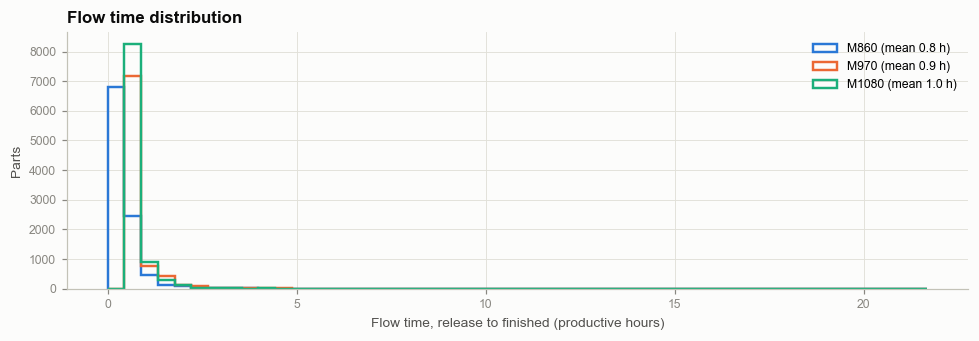

,Avg flow time (hr),P90 flow time (hr)
Model,,
M860,0.790,0.858
M970,0.926,1.331
M1080,1.032,1.056
Total,0.914,1.077


In [13]:
P.plot_flow_time(res); plt.show()
display(res.throughput[["Avg flow time (hr)", "P90 flow time (hr)"]])


## 11. Replications and policy comparisons

Six policies, each with ten replications (seeds 1–10): your partner's four from `phase2_assumptions_simulation.ipynb` (continuous product runs, cyclic with per-machine changeovers, cyclic + workcell with and without SPC) plus heijunka + workcell with and without SPC. The no-SPC references retain original scrap probabilities. SPC reduces planned scrap allowances and therefore input kit requirements and arrival frequency; demand targets are unchanged. Check the per-model table: cyclic meets total demand while under-building M860 and over-building M970. Reported half-widths are 95% confidence intervals for the mean.

In [14]:
cyclic_spc = get_scenario(YEAR, release_mode="cyclic", setup_scope="workcell", setup_crew=SETUP_CREW,
                          scrap_scale=SPC_SCRAP_SCALE)
policies = {
    "Continuous product runs": get_scenario(YEAR, release_mode="continuous"),
    "Unit rotation: machine changeovers": get_scenario(YEAR, release_mode="cyclic"),
    "Unit rotation: assumptions (no SPC)": replace(cyclic_spc, scrap_scale=1.0),
    "Unit rotation: assumptions": cyclic_spc,
    "Heijunka + workcell (no SPC)": replace(sc, scrap_scale=1.0),
    "Heijunka + workcell": sc,
}
summaries = {}
for name, scenario in policies.items():
    print("Running:", name, flush=True)
    _, summaries[name] = run_replications(scenario, n=N_REPS, n_jobs=N_JOBS)
keys = [
    ("WIP", "Average WIP (parts)"), ("WIP", "Ending WIP (parts)"),
    ("Throughput", "Total per week"), ("Throughput", "% of demand"),
    *[("Throughput", f"{model} per week") for model in MODELS],
    *[("Flow time (hr)", model) for model in MODELS],
    ("Scrap", "Items scrapped per week"),
    ("Operators", "Fab utilization"), ("Operators", "Asm utilization"),
]
comparison = pd.concat([summary.loc[keys, "Average"].rename(name) for name, summary in summaries.items()], axis=1)
display(comparison)

# Each model's weekly output as a share of its own weekly demand
demand_wk = {m: sc.demand[m] / 50 for m in MODELS}
by_model = pd.DataFrame({name: {m: s.loc[("Throughput", f"{m} per week"), "Average"] / demand_wk[m]
                                for m in MODELS} for name, s in summaries.items()})
display(by_model.style.format("{:.1%}").set_caption("Output as % of each model's demand"))

assumptions_summary = summaries["Heijunka + workcell"]
display(assumptions_summary.loc[keys, ["Average", "Half Width", "Minimum", "Maximum"]])
comparison.to_csv("heijunka_comparison.csv")

Running: Continuous product runs
Running: Unit rotation: machine changeovers
Running: Unit rotation: assumptions (no SPC)
Running: Unit rotation: assumptions
Running: Heijunka + workcell (no SPC)
Running: Heijunka + workcell


Continuous product runs  Unit rotation: machine changeovers  Unit rotation: assumptions (no SPC)  Unit rotation: assumptions  Heijunka + workcell (no SPC)  \
Category       Statistic                                                                                                                                                                             
WIP            Average WIP (parts)                      940.680                          36,496.965                              180.025                      72.389                       174.572   
               Ending WIP (parts)                       754.000                          60,729.000                              159.300                      76.900                       137.200   
Throughput     Total per week                         3,608.675                             644.275                            3,618.213                   3,614.613                     3,603.825   
               % of demand                                0.999                               0.178                                1.001                       1.000                         0.997   
               M860 per week                          1,311.150                             204.675                            1,148.275                   1,189.375                     1,276.263   
               M970 per week                          1,110.062                             223.225                            1,246.450                   1,216.425                     1,103.362   
               M1080 per week                         1,187.463                             216.375                            1,223.487                   1,208.812                     1,224.200   
Flow time (hr) M860                                      14.468                             382.046                                1.964                       0.801                         1.823   
               M970                                      15.102                             380.197                                1.609                       0.936                         1.641   
               M1080                                     13.184                             379.646                                2.090                       1.073                         1.983   
Scrap          Items scrapped per week                  933.350                             239.900                              912.362                     207.600                       926.225   
Operators      Fab utilization                            0.881                               1.000                                0.877                       0.769                         0.881   
               Asm utilization                            0.870                               0.175                                0.894                       0.854                         0.874   

                                        Heijunka + workcell  
Category       Statistic                                     
WIP            Average WIP (parts)                   70.147  
               Ending WIP (parts)                    61.500  
Throughput     Total per week                     3,612.975  
               % of demand                            1.000  
               M860 per week                      1,278.425  
               M970 per week                      1,106.537  
               M1080 per week                     1,228.013  
Flow time (hr) M860                                   0.760  
               M970                                   0.943  
               M1080                                  1.022  
Scrap          Items scrapped per week              210.000  
Operators      Fab utilization                        0.773  
               Asm utilization                        0.843

,Continuous product runs,Unit rotation: machine changeovers,Unit rotation: assumptions (no SPC),Unit rotation: assumptions,Heijunka + workcell (no SPC),Heijunka + workcell
M860,102.6%,16.0%,89.9%,93.1%,99.9%,100.1%
M970,100.4%,20.2%,112.7%,110.0%,99.8%,100.1%
M1080,96.5%,17.6%,99.4%,98.3%,99.5%,99.8%


Average  Half Width   Minimum   Maximum
Category       Statistic                                                        
WIP            Average WIP (parts)        70.147       1.799    67.406    74.420
               Ending WIP (parts)         61.500       6.593    45.000    73.000
Throughput     Total per week          3,612.975       2.505 3,607.875 3,618.750
               % of demand                 1.000       0.001     0.998     1.001
               M860 per week           1,278.425       1.365 1,275.875 1,281.750
               M970 per week           1,106.537       0.791 1,105.000 1,108.250
               M1080 per week          1,228.013       1.589 1,225.375 1,231.125
Flow time (hr) M860                        0.760       0.019     0.723     0.801
               M970                        0.943       0.022     0.893     1.006
               M1080                       1.022       0.024     0.965     1.073
Scrap          Items scrapped per week   210.000       2.980   201.125   214.125
Operators      Fab utilization             0.773       0.000     0.773     0.773
               Asm utilization             0.843       0.001     0.842     0.844

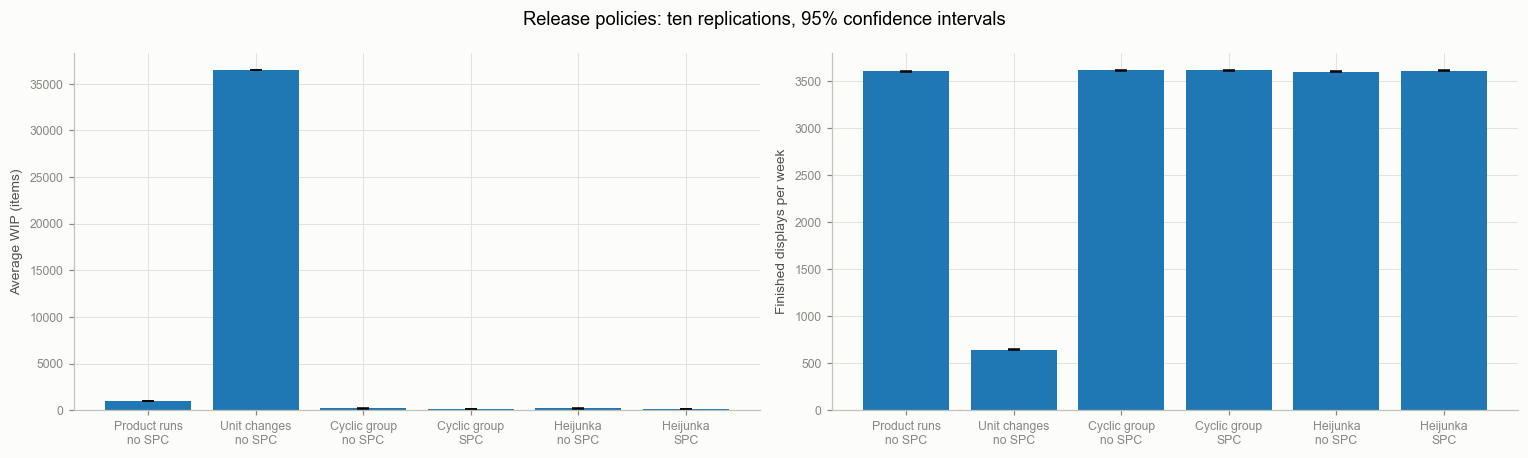

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
labels = ["Product runs\nno SPC", "Unit changes\nno SPC", "Cyclic group\nno SPC", "Cyclic group\nSPC",
          "Heijunka\nno SPC", "Heijunka\nSPC"]
for ax, key, label in zip(axes, [("WIP", "Average WIP (parts)"), ("Throughput", "Total per week")],
                         ["Average WIP (items)", "Finished displays per week"]):
    means = [summary.loc[key, "Average"] for summary in summaries.values()]
    errors = [summary.loc[key, "Half Width"] for summary in summaries.values()]
    ax.bar(labels, means, yerr=errors, capsize=4)
    ax.tick_params(axis="x", labelsize=8)
    ax.set_ylabel(label)
fig.suptitle("Release policies: ten replications, 95% confidence intervals")
fig.tight_layout(); plt.show()

## 12. Bottlenecks across replications

Station utilization and average queues are averaged across the heijunka + workcell (SPC) replications. High utilization and persistent queues identify constraints; machine Setup and Waiting for operator states explain capacity losses.

,Avg utilization (10 reps),Avg queue (10 reps),Machines,Setup %,WaitOp %,Group setups
Statistic,,,,,,
9-M,0.867,1.831,6,0.000,0.001,13
10-M,0.851,0.223,5,0.001,0.001,13
1-M,0.830,0.338,2,0.002,0.014,13
5-A,0.768,0.641,6,0.015,0.005,43
8-A,0.688,0.985,2,0.004,0.020,43
11-A,0.681,0.314,2,0.004,0.017,43
2-M,0.608,0.037,2,0.002,0.020,13
4-A,0.607,0.899,1,0.003,0.049,43
6-A,0.600,0.241,3,0.001,0.031,13


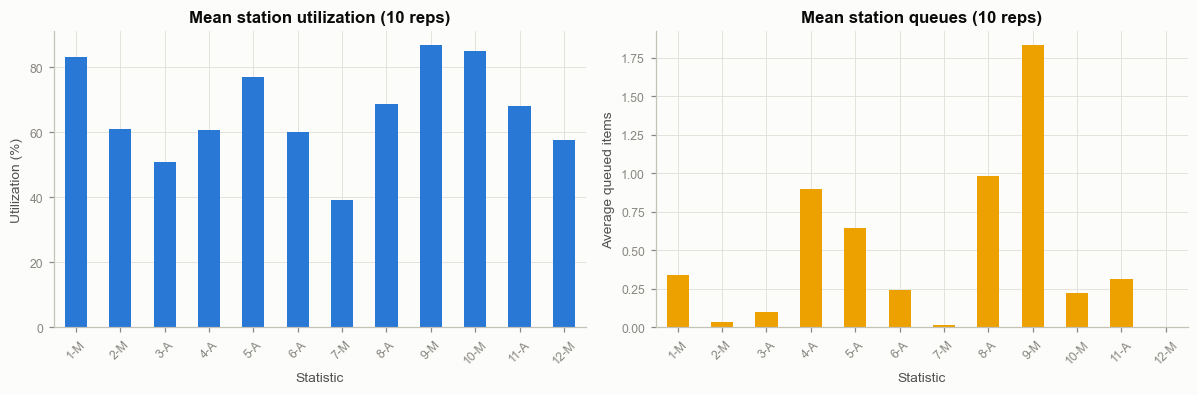

Average  Half Width   Minimum   Maximum
Category            Statistic                                                                    
Throughput          M860 per week                       1,278.425       1.365 1,275.875 1,281.750
                    M970 per week                       1,106.537       0.791 1,105.000 1,108.250
                    M1080 per week                      1,228.013       1.589 1,225.375 1,231.125
                    Total per week                      3,612.975       2.505 3,607.875 3,618.750
                    % of demand                             1.000       0.001     0.998     1.001
Flow time (hr)      M860                                    0.760       0.019     0.723     0.801
                    M970                                    0.943       0.022     0.893     1.006
                    M1080                                   1.022       0.024     0.965     1.073
WIP                 Average WIP (parts)                    70.147       1.799    67.406    74.420
                    Ending WIP (parts)                     61.500       6.593    45.000    73.000
Operators           Fab utilization                         0.773       0.000     0.773     0.773
                    Fab wait for operator (min/part)        0.054       0.000     0.053     0.054
                    Asm utilization                         0.843       0.001     0.842     0.844
                    Asm wait for operator (min/part)        0.019       0.001     0.017     0.020
Station utilization 1-M                                     0.830       0.000     0.830     0.830
                    2-M                                     0.608       0.000     0.608     0.608
                    3-A                                     0.508       0.000     0.508     0.508
                    4-A                                     0.607       0.000     0.607     0.607
                    5-A                                     0.768       0.000     0.768     0.768
                    6-A                                     0.600       0.000     0.600     0.600
                    7-M                                     0.390       0.000     0.390     0.390
                    8-A                                     0.688       0.000     0.687     0.688
                    9-M                                     0.867       0.000     0.866     0.868
                    10-M                                    0.851       0.001     0.849     0.852
                    11-A                                    0.681       0.000     0.681     0.683
                    12-M                                    0.575       0.000     0.574     0.576
Avg queue           1-M                                     0.338       0.002     0.334     0.341
                    2-M                                     0.037       0.002     0.033     0.041
                    3-A                                     0.100       0.011     0.083     0.124
                    4-A                                     0.899       0.005     0.887     0.907
                    5-A                                     0.641       0.119     0.425     0.946
                    6-A                                     0.241       0.087     0.113     0.433
                    7-M                                     0.011       0.000     0.011     0.011
                    8-A                                     0.985       0.079     0.816     1.140
                    9-M                                     1.831       0.180     1.508     2.214
                    10-M                                    0.223       0.006     0.211     0.239
                    11-A                                    0.314       0.041     0.236     0.438
                    12-M                                    0.001       0.000     0.001     0.001
Down %              1-M                                     0.000       0.000     0.000     0.000
                    2-M                 

In [16]:
summary = assumptions_summary
avg_util = summary.xs("Station utilization").Average.rename("Avg utilization (10 reps)")
avg_q = summary.xs("Avg queue").Average.rename("Avg queue (10 reps)")
bottlenecks = pd.concat([avg_util, avg_q], axis=1).join(res.stations[["Machines", "Setup %", "WaitOp %", "Group setups"]])
display(bottlenecks.sort_values("Avg utilization (10 reps)", ascending=False))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
avg_util.reindex(STATIONS).mul(100).plot.bar(ax=axes[0], color="#2a78d6", rot=45)
axes[0].set_ylabel("Utilization (%)")
axes[0].set_title("Mean station utilization (10 reps)")
avg_q.reindex(STATIONS).plot.bar(ax=axes[1], color="#eda100", rot=45)
axes[1].set_ylabel("Average queued items")
axes[1].set_title("Mean station queues (10 reps)")
fig.tight_layout(); plt.show()
display(summary)
